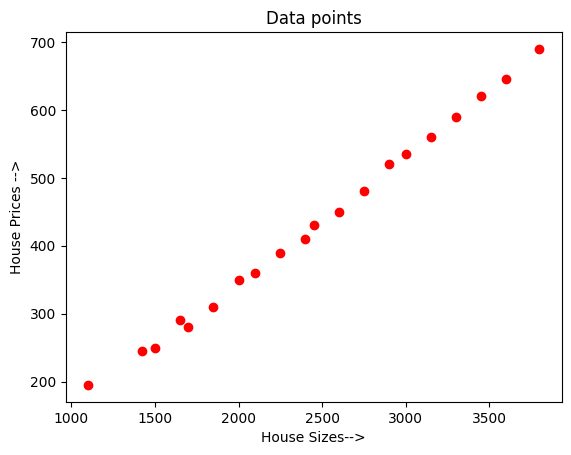

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# House sizes in square feet (will be divided by 1000 in your code -> 1.1 to 3.8)
house_size = [
    1100, 1420, 1500, 1650, 1700, 1850, 2000, 2100, 2250, 2400,
    2450, 2600, 2750, 2900, 3000, 3150, 3300, 3450, 3600, 3800
]

# House prices (in thousands) matching the sizes with a bit of noise
house_price = [
    195, 245, 250, 290, 280, 310, 350, 360, 390, 410,
    430, 450, 480, 520, 535, 560, 590, 620, 645, 690
]

plt.scatter(house_size, house_price, marker='o', color = 'Red')
plt.xlabel('House Sizes-->')
plt.ylabel('House Prices -->')
plt.title('Data points')
plt.show()

In [2]:
x = [i/1000 for i in house_size]
y = [i/1000 for i in house_price]
lengthy = len(x)

In [3]:
def f(w0,w1):

    summation_of_error = 0
    for i in range(lengthy):
        error = y[i] - (w0 + w1*x[i])
        summation_of_error = summation_of_error + (error)**2

    return (1/(2*lengthy)) * summation_of_error

def gradient(w0,w1):

    summation_of_error_w0 = 0
    summation_of_error_w1 = 0

    for i in range(lengthy):
        error = y[i] - (w0 + w1*x[i])

        summation_of_error_w0 = summation_of_error_w0 + error
        summation_of_error_w1 = summation_of_error_w1 + (error*x[i])

    df_dx = - 1/lengthy * summation_of_error_w0
    df_dy = - 1/lengthy* summation_of_error_w1

    return np.array([df_dx,df_dy])

def hessian():

    derivative_with_w0_2nd_time = 1

    summation_of_xi = 0
    summation_of_xi2 = 0
    for i in x:
        summation_of_xi += i
        summation_of_xi2 += i**2
    derivative_with_w0w1_2nd_time = 1/lengthy * summation_of_xi
    derivative_with_w1_2nd_time = 1/lengthy * summation_of_xi2

    return np.array([[derivative_with_w0_2nd_time, derivative_with_w0w1_2nd_time],
                     [derivative_with_w0w1_2nd_time, derivative_with_w1_2nd_time]])


In [4]:
tol = 1e-6
k = 0
max_iter = 1000
alpha = 1
w= np.array([0,0])

In [5]:
store_w0_data = [w[0]]
store_w1_data = [w[1]]
store_z_data = [f(w[0],w[1])]

In [6]:
while np.linalg.norm(gradient(w[0],w[1])) > tol and max_iter>k:

    #direction =
    direction = - (np.linalg.inv(hessian())@gradient(w[0],w[1]))

    #new pos = 
    newpos = w + (alpha * direction)

    #update:
    w = newpos

    k += 1

    #store
    store_w0_data.append(w[0])
    store_w1_data.append(w[1])
    store_z_data.append(f(w[0], w[1]))

    print(f'[Epoch {k}]  Current Knobs {w}, Current height {f(w[0],w[1])}')


[Epoch 1]  Current Knobs [-0.02579819  0.18615405], Current height 2.43235535382143e-05


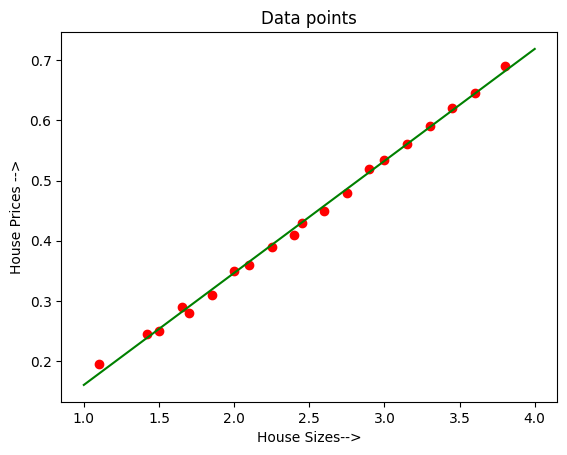

In [7]:
plt.scatter(x, y, marker='o', color = 'Red')
plt.xlabel('House Sizes-->')
plt.ylabel('House Prices -->')
plt.title('Data points')

X = np.linspace(min(x)-0.1, max(x)+0.2,100)
Y = w[0] + w[1]*X

plt.plot(X,Y, color='Green')

plt.show()

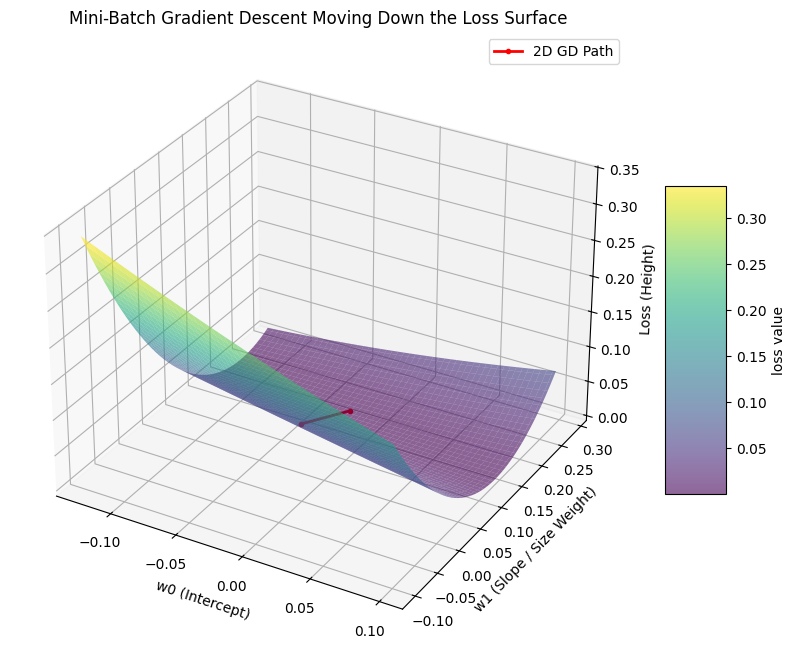

In [13]:
fig = plt.figure(figsize=(10,8))
ax = fig.add_subplot(projection='3d')

X_surf = np.linspace(min(store_w0_data)-0.1, max(store_w0_data)+0.1, 100)
Y_surf = np.linspace(min(store_w1_data)-0.1, max(store_w1_data)+0.1, 100)
X,Y = np.meshgrid(X_surf,Y_surf)
Z = f(X,Y)

surf = ax.plot_surface(X,Y,Z, cmap='viridis', alpha=0.6)
fig.colorbar(surf, ax=ax, shrink= 0.5, aspect=5, label='loss value')

ax.plot(store_w0_data, store_w1_data, store_z_data, color = 'Red', marker='.', linewidth = 2,label='2D GD Path')

ax.set_xlabel('w0 (Intercept)')
ax.set_ylabel('w1 (Slope / Size Weight)')
ax.set_zlabel('Loss (Height)')
ax.set_title('Mini-Batch Gradient Descent Moving Down the Loss Surface')
ax.legend()
plt.show()